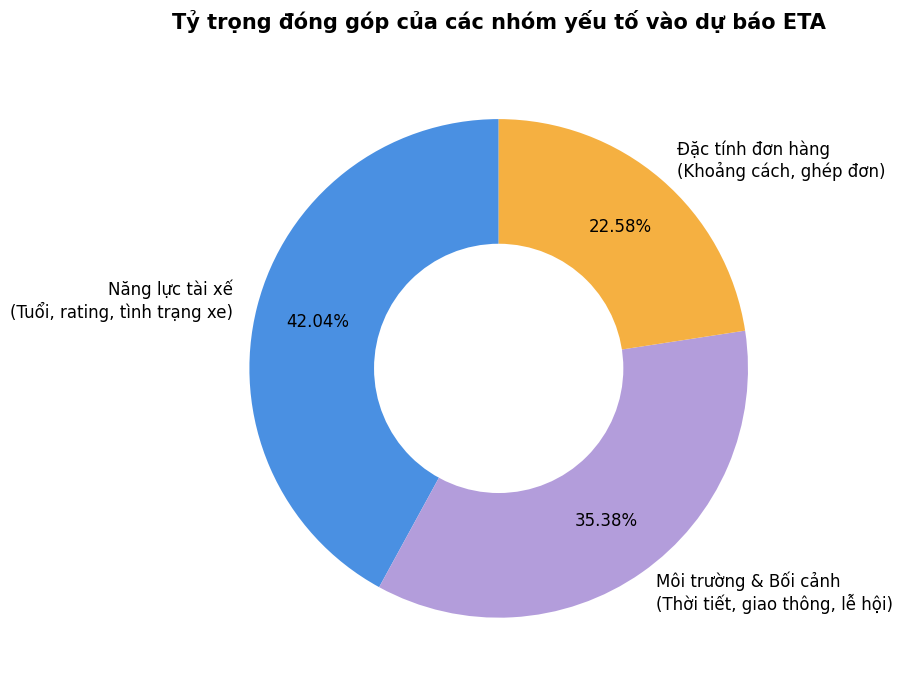

In [ ]:
import matplotlib.pyplot as plt

# Dữ liệu đã được tính toán chính xác từ kết quả Feature Importance
labels =[
    'Năng lực tài xế\n(Tuổi, rating, tình trạng xe)',
    'Môi trường & Bối cảnh\n(Thời tiết, giao thông, lễ hội)',
    'Đặc tính đơn hàng\n(Khoảng cách, ghép đơn)'
]
sizes = [42.04, 35.38, 22.58] # Tổng = 100%
colors = ['#4A90E2', '#B39DDB', '#F5B041'] # Bảng màu thanh lịch

plt.figure(figsize=(9, 7))
# Vẽ biểu đồ tròn
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.2f%%',
        startangle=90, pctdistance=0.75, textprops={'fontsize': 12})

# Tạo vòng tròn trắng ở giữa để thành Donut Chart
centre_circle = plt.Circle((0,0),0.50,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Tỷ trọng đóng góp của các nhóm yếu tố vào dự báo ETA',
          fontsize=15, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

Mounted at /content/drive


/tmp/ipykernel_151/1818289038.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='multiple_deliveries', y='Time_taken (min)', data=df_plot, palette='viridis')


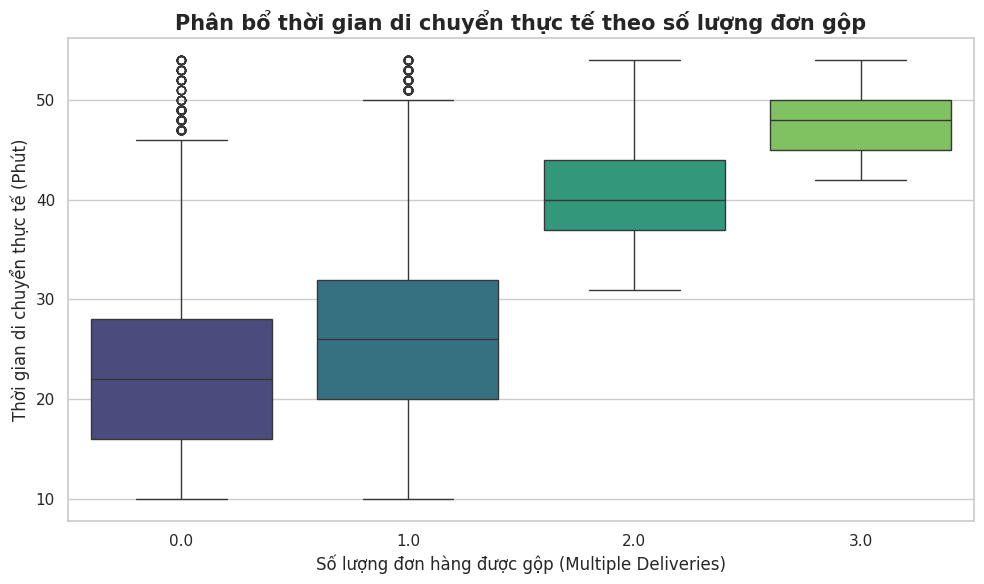

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive

# 1. Kết nối Drive (Colab sẽ hiện thông báo xác nhận, bạn nhấn đồng ý nhé)
drive.mount('/content/drive')

# 2. Đường dẫn file lấy từ code EDA của bạn
path = '/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/Zomato Dataset.csv'

# 3. Đọc và Tiền xử lý nhanh (theo logic EDA bạn gửi)
df = pd.read_csv(path)

# Làm sạch khoảng trắng dư thừa trong tên cột và dữ liệu chuỗi
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Chuyển đổi multiple_deliveries sang dạng số, bỏ qua các giá trị lỗi/NaN để vẽ boxplot đẹp hơn
df['multiple_deliveries'] = pd.to_numeric(df['multiple_deliveries'], errors='coerce')
df_plot = df.dropna(subset=['multiple_deliveries', 'Time_taken (min)'])

# 4. Vẽ biểu đồ cho Insight 3
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Vẽ Boxplot
sns.boxplot(x='multiple_deliveries', y='Time_taken (min)', data=df_plot, palette='viridis')

# Cập nhật tiêu đề chuyên nghiệp
plt.title('Phân bổ thời gian di chuyển thực tế theo số lượng đơn gộp', fontsize=15, fontweight='bold')
plt.xlabel('Số lượng đơn hàng được gộp (Multiple Deliveries)', fontsize=12)
plt.ylabel('Thời gian di chuyển thực tế (Phút)', fontsize=12)

plt.tight_layout()
plt.show()

/tmp/ipykernel_151/3228820699.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Importance', y='Feature', data=df_i4, palette='magma')


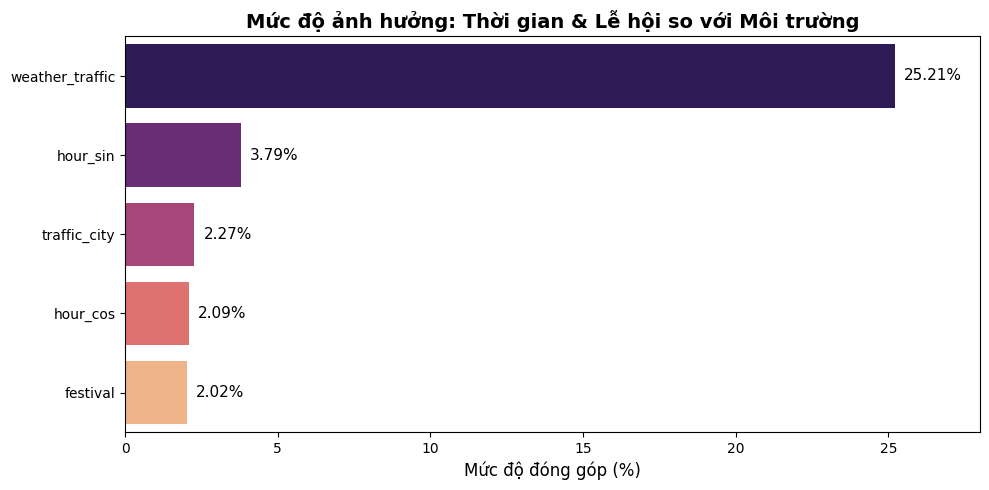

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Tạo dữ liệu trực tiếp
data_insight4 = {
    'Feature':['weather_traffic', 'hour_sin', 'traffic_city', 'hour_cos', 'festival'],
    'Importance':[25.21, 3.79, 2.27, 2.09, 2.02]
}
df_i4 = pd.DataFrame(data_insight4)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x='Importance', y='Feature', data=df_i4, palette='magma')

plt.title('Mức độ ảnh hưởng: Thời gian & Lễ hội so với Môi trường', fontsize=14, fontweight='bold')
plt.xlabel('Mức độ đóng góp (%)', fontsize=12)
plt.ylabel('', fontsize=12)

# Gắn số % trực tiếp lên đuôi mỗi thanh bar
for index, value in enumerate(df_i4['Importance']):
    plt.text(value + 0.3, index, f'{value}%', va='center', fontsize=11)

plt.xlim(0, 28) # Mở rộng trục X để không bị lẹm chữ
plt.tight_layout()
plt.show()

/tmp/ipykernel_151/1720978859.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Yếu tố', y='Importance', data=df_i5, palette=['#2C3E50', '#95A5A6'])


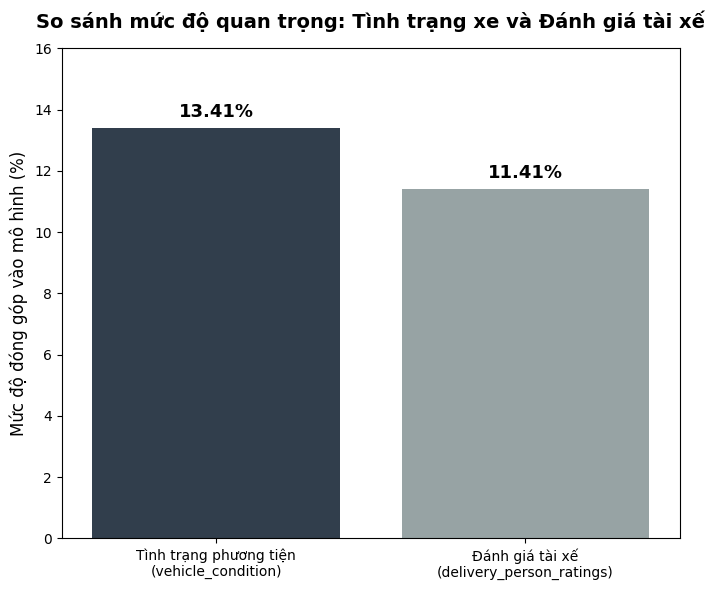

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Tạo dữ liệu trực tiếp
data_insight5 = {
    'Yếu tố': ['Tình trạng phương tiện\n(vehicle_condition)', 'Đánh giá tài xế\n(delivery_person_ratings)'],
    'Importance': [13.41, 11.41]
}
df_i5 = pd.DataFrame(data_insight5)

plt.figure(figsize=(7, 6))
# Sử dụng màu sắc chuyên nghiệp hơn (Xanh navy và Xám bạc chẳng hạn)
ax = sns.barplot(x='Yếu tố', y='Importance', data=df_i5, palette=['#2C3E50', '#95A5A6'])

# Đổi tên tiêu đề ở đây
plt.title('So sánh mức độ quan trọng: Tình trạng xe và Đánh giá tài xế', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Mức độ đóng góp vào mô hình (%)', fontsize=12)
plt.xlabel('', fontsize=12)
plt.ylim(0, 16)

# Gắn số % trên đỉnh cột
for p in ax.patches:
    ax.annotate(f'{p.get_height()}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom',
                fontsize=13, fontweight='bold', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()